<a href="https://colab.research.google.com/github/Njeon3091/AICE_study/blob/main/Epass_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

In [85]:
#import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 폰트 패키지 설치 및 캐시 삭제
!sudo apt-get update -qq
!sudo apt-get install -y fonts-nanum > /dev/null
!rm -rf ~/.cache/matplotlib

# 폰트 매니저에 직접 등록
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False
print("폰트 설정 완료")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
폰트 설정 완료


In [86]:
import seaborn as sns

In [87]:
car_df = pd.read_csv("1_used_car_prices.csv")
car_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                961 non-null    object 
 1   age_years            1000 non-null   float64
 2   mileage_km           1000 non-null   float64
 3   engine_type          979 non-null    object 
 4   engine_size_cc       1000 non-null   float64
 5   horsepower           1000 non-null   float64
 6   fuel_efficiency_kml  1000 non-null   float64
 7   accident_count       1000 non-null   float64
 8   color                968 non-null    object 
 9   option_grade         973 non-null    object 
 10  price_krw            1000 non-null   float64
dtypes: float64(7), object(4)
memory usage: 86.1+ KB


In [88]:
car_df.head()

,brand,age_years,mileage_km,engine_type,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,option_grade,price_krw
0,B사,14.0,218413.0,전기,3253.0,333.0,8.6,3.0,검정,고급,100.0
1,D사,11.0,90552.0,하이브리드,3294.0,327.0,8.3,0.0,은색,고급,100.0
2,C사,13.0,178150.0,디젤,3805.0,387.0,4.8,0.0,흰색,중급,100.0
3,NaN,7.0,127044.0,하이브리드,1146.0,110.0,19.2,2.0,기타,고급,100.0
4,A사,2.0,40116.0,디젤,3165.0,340.0,8.9,0.0,은색,고급,3987.0


/tmp/ipykernel_1883/1405527486.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


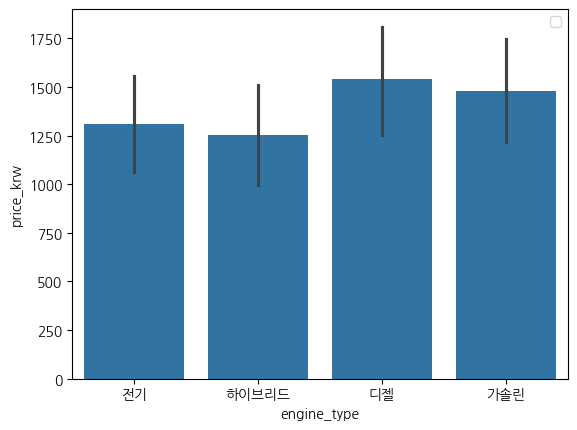

In [89]:
car_df['engine_type'].value_counts()

plt.figure()
sns.barplot(x = car_df['engine_type'], y = car_df['price_krw'])
plt.legend()
plt.show()

In [90]:
car_df.head()

,brand,age_years,mileage_km,engine_type,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,option_grade,price_krw
0,B사,14.0,218413.0,전기,3253.0,333.0,8.6,3.0,검정,고급,100.0
1,D사,11.0,90552.0,하이브리드,3294.0,327.0,8.3,0.0,은색,고급,100.0
2,C사,13.0,178150.0,디젤,3805.0,387.0,4.8,0.0,흰색,중급,100.0
3,NaN,7.0,127044.0,하이브리드,1146.0,110.0,19.2,2.0,기타,고급,100.0
4,A사,2.0,40116.0,디젤,3165.0,340.0,8.9,0.0,은색,고급,3987.0


In [91]:
car_df.groupby(['brand', 'option_grade'])['price_krw'].mean()

brand  option_grade
A사     고급              1261.629630
       기본              1188.489583
       중급              1314.852632
B사     고급              1539.666667
       기본              1503.191489
       중급              1877.250000
C사     고급              1165.759259
       기본              1924.813559
       중급              1316.819672
D사     고급              1467.735849
       기본              1218.375000
       중급              1019.464286
Name: price_krw, dtype: float64

In [92]:
car_df.head()

,brand,age_years,mileage_km,engine_type,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,option_grade,price_krw
0,B사,14.0,218413.0,전기,3253.0,333.0,8.6,3.0,검정,고급,100.0
1,D사,11.0,90552.0,하이브리드,3294.0,327.0,8.3,0.0,은색,고급,100.0
2,C사,13.0,178150.0,디젤,3805.0,387.0,4.8,0.0,흰색,중급,100.0
3,NaN,7.0,127044.0,하이브리드,1146.0,110.0,19.2,2.0,기타,고급,100.0
4,A사,2.0,40116.0,디젤,3165.0,340.0,8.9,0.0,은색,고급,3987.0


In [93]:
car_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                961 non-null    object 
 1   age_years            1000 non-null   float64
 2   mileage_km           1000 non-null   float64
 3   engine_type          979 non-null    object 
 4   engine_size_cc       1000 non-null   float64
 5   horsepower           1000 non-null   float64
 6   fuel_efficiency_kml  1000 non-null   float64
 7   accident_count       1000 non-null   float64
 8   color                968 non-null    object 
 9   option_grade         973 non-null    object 
 10  price_krw            1000 non-null   float64
dtypes: float64(7), object(4)
memory usage: 86.1+ KB


In [101]:
car_pre = car_df.copy()

In [102]:
car_pre['option_grade'].value_counts()

,count
option_grade,
기본,341
고급,332
중급,300


In [103]:
car_pre.columns

Index(['brand', 'age_years', 'mileage_km', 'engine_type', 'engine_size_cc',
       'horsepower', 'fuel_efficiency_kml', 'accident_count', 'color',
       'option_grade', 'price_krw'],
      dtype='object')

In [105]:
mode_df = car_pre['option_grade'].mode()[0]
car_pre['option_grade'].fillna(mode_df, inplace=True)

#car_pre = car_df_na[cols]

In [106]:
mode_df

'기본'

In [107]:
car_pre.head()

,brand,age_years,mileage_km,engine_type,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,option_grade,price_krw
0,B사,14.0,218413.0,전기,3253.0,333.0,8.6,3.0,검정,고급,100.0
1,D사,11.0,90552.0,하이브리드,3294.0,327.0,8.3,0.0,은색,고급,100.0
2,C사,13.0,178150.0,디젤,3805.0,387.0,4.8,0.0,흰색,중급,100.0
3,NaN,7.0,127044.0,하이브리드,1146.0,110.0,19.2,2.0,기타,고급,100.0
4,A사,2.0,40116.0,디젤,3165.0,340.0,8.9,0.0,은색,고급,3987.0


In [108]:
car_pre.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                961 non-null    object 
 1   age_years            1000 non-null   float64
 2   mileage_km           1000 non-null   float64
 3   engine_type          979 non-null    object 
 4   engine_size_cc       1000 non-null   float64
 5   horsepower           1000 non-null   float64
 6   fuel_efficiency_kml  1000 non-null   float64
 7   accident_count       1000 non-null   float64
 8   color                968 non-null    object 
 9   option_grade         1000 non-null   object 
 10  price_krw            1000 non-null   float64
dtypes: float64(7), object(4)
memory usage: 86.1+ KB


In [109]:
car_pre['option_grade'].value_counts()

,count
option_grade,
기본,368
고급,332
중급,300


In [110]:
cols = ['brand', 'age_years', 'mileage_km', 'engine_type', 'engine_size_cc','horsepower', 'fuel_efficiency_kml', 'accident_count','option_grade', 'price_krw']

car_pre = car_pre[cols]

In [111]:
car_pre.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                961 non-null    object 
 1   age_years            1000 non-null   float64
 2   mileage_km           1000 non-null   float64
 3   engine_type          979 non-null    object 
 4   engine_size_cc       1000 non-null   float64
 5   horsepower           1000 non-null   float64
 6   fuel_efficiency_kml  1000 non-null   float64
 7   accident_count       1000 non-null   float64
 8   option_grade         1000 non-null   object 
 9   price_krw            1000 non-null   float64
dtypes: float64(7), object(3)
memory usage: 78.3+ KB
